# BGC-Argo POC flux distribution: data (steps 0-2)

| Step | Content | Status |
|---|---|---|
| 0 | Combine the relevant source data into one Excel file | Done |
| 1 | Check the distribution of the raw values at each depth | Done |
| 2 | Data cleaning | Done |

Step 3 is in `step3_fit_model.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SRC = Path("source")
PROJ = Path(".")
TAGS = SRC / "cycles_biome_tags_v3_0531.csv"
XLSX = PROJ / "source_data_perdepth.xlsx"

## Step 0: Combine the source data

**Aim:** Put the per-depth concentrations, profile information, SST, Chl-a and deep BBP into one Excel file, without removing any row.

In [2]:
# One row per profile: date, position, region tags, deep BBP
profiles = pd.read_csv(TAGS, low_memory=False)
deep = pd.read_csv(SRC / "deep_bbp_per_cycle_v3_1103.csv", low_memory=False)
profiles = profiles.merge(deep.drop(columns=["read_error", "spoc_max"]), on="cycle_uid", how="left")
profiles["high_deep_bbp"] = profiles["deep_bbp_med"] > 0.005

# Covariates: same-day values match on cycle_uid, monthly values on 1 deg cell and month
lon = (profiles["lon"] + 180) % 360 - 180
profiles["month_key"] = (np.floor(profiles["lat"]).astype("Int64").astype(str) + "_"
                         + np.floor(lon).astype("Int64").astype(str) + "_"
                         + pd.to_datetime(profiles["date"]).dt.strftime("%Y-%m"))

def add_covariate(table, name, key):
    values = pd.read_csv(SRC / "covariates" / f"{name}_v3_1103.csv").set_index("key")["value"]
    table[name] = table[key].map(values)

add_covariate(profiles, "sst_day", "cycle_uid")
add_covariate(profiles, "chl_day", "cycle_uid")
add_covariate(profiles, "sst_month", "month_key")
add_covariate(profiles, "chl_month", "month_key")

In [3]:
# One row per profile and depth: +-10 dbar window mean concentrations and flux
depths = pd.read_csv(SRC / "perdepth_conc_v3_1103.csv", low_memory=False)
depths["F_5_12"] = 5 * depths["spoc_mean"] + 12 * depths["lpoc_mean_zoo0"]
depths["F_5_74"] = 5 * depths["spoc_mean"] + 74 * depths["lpoc_mean_zoo0"]
depths = depths.merge(profiles[["cycle_uid", "high_deep_bbp"]], on="cycle_uid", how="left")

In [4]:
readme = pd.DataFrame([
    ("depth_values", "spoc_mean, lpoc_mean_all", "window mean concentration, all levels (mmol C m-3)"),
    ("depth_values", "spoc_mean_le20", "sPOC mean over levels <= 20 mmol C m-3"),
    ("depth_values", "lpoc_mean_zoo0", "lPOC mean over zoo_excluded = 0 levels"),
    ("depth_values", "n_*", "number of levels in the +-10 dbar window"),
    ("depth_values", "F_5_12", "5 x spoc_mean + 12 x lpoc_mean_zoo0 (mmol C m-2 d-1)"),
    ("depth_values", "F_5_74", "5 x spoc_mean + 74 x lpoc_mean_zoo0 (mmol C m-2 d-1)"),
    ("both", "high_deep_bbp", "median BBP below 500 dbar > 0.005 m-1; rows kept, only flagged"),
    ("profiles", "deep_bbp_med, deep_bbp_p95", "BBP below 500 dbar (m-1)"),
    ("profiles", "sst_day, chl_day", "same day, +-0.5 deg box median (deg C; mg m-3)"),
    ("profiles", "sst_month, chl_month", "1 deg monthly mean (deg C; mg m-3)"),
], columns=["sheet", "column", "meaning"])

with pd.ExcelWriter(XLSX) as writer:
    readme.to_excel(writer, sheet_name="README", index=False)
    depths.to_excel(writer, sheet_name="depth_values", index=False)
    profiles.to_excel(writer, sheet_name="profiles", index=False)

print("depth_values", depths.shape, "| profiles", profiles.shape, f"| {XLSX.stat().st_size / 1e6:.0f} MB")
print(profiles[["sst_day", "chl_day", "sst_month", "chl_month"]].notna().sum().to_dict())

depth_values (322580, 18) | profiles (80645, 30) | 52 MB
{'sst_day': 79299, 'chl_day': 75449, 'sst_month': 79299, 'chl_month': 76638}


**Conclusion:** The Excel file is written (52 MB). `depth_values` has 322,580 rows and `profiles` has 80,645 rows; no row was removed. 79,299 profiles have SST, 75,449 have same-day Chl-a and 76,638 have monthly Chl-a. The per-level CSVs are not included; the file holds ±10 dbar window means.

## Step 1: Distribution of the raw values at each depth

**Aim:** Read `F_5_12` from the Excel file, without taking logs or removing the profiles with high deep BBP, and look at the percentiles and histograms at each depth.

In [5]:
data = pd.read_excel(XLSX, sheet_name="depth_values")
flux = data[data["F_5_12"] > 0]

counts = data.groupby("depth")["F_5_12"].agg(
    rows="size", empty=lambda f: f.isna().sum(), not_positive=lambda f: (f <= 0).sum(), positive=lambda f: (f > 0).sum())
counts["positive_high_deep_bbp"] = flux.groupby("depth")["high_deep_bbp"].sum()
counts

,rows,empty,not_positive,positive,positive_high_deep_bbp
depth,,,,,
100,80645,72,0,80573,111
200,80645,286,0,80359,111
500,80645,1742,0,78903,111
900,80645,3206,0,77439,108


In [6]:
percentiles = [0, .01, .05, .25, .5, .75, .95, .99, .999, 1]
stats = flux.groupby("depth")["F_5_12"].quantile(percentiles).unstack()
stats.columns = ["min", "P1", "P5", "P25", "P50", "P75", "P95", "P99", "P99.9", "max"]
stats["mean"] = flux.groupby("depth")["F_5_12"].mean()
stats.to_csv(PROJ / "step1_raw_flux_stats.csv")
stats.round(3)

,min,P1,P5,P25,P50,P75,P95,P99,P99.9,max,mean
depth,,,,,,,,,,,
100,0.371,3.134,4.208,6.641,8.723,11.352,20.062,38.564,387.639,7640106.194,105.990
200,0.003,1.726,2.298,3.195,3.965,4.968,8.161,15.649,164.045,4336569.102,59.200
500,0.145,0.697,1.050,1.454,1.779,2.198,3.585,7.613,90.091,2010079.980,27.881
900,0.029,0.473,0.780,1.090,1.347,1.672,2.730,5.724,112.289,1730180.521,24.228


In [7]:
# Extreme values: all data compared with the flagged high deep BBP profiles left out
kept = flux[~flux["high_deep_bbp"]].groupby("depth")["F_5_12"]
pd.DataFrame({
    "above_1000": flux[flux["F_5_12"] > 1000].groupby("depth").size(),
    "above_1000_kept": flux[(flux["F_5_12"] > 1000) & ~flux["high_deep_bbp"]].groupby("depth").size(),
    "max_all": stats["max"], "max_kept": kept.max(),
    "mean_all": stats["mean"], "mean_kept": kept.mean(), "P50_kept": kept.median(),
}).fillna(0).round(2)

,above_1000,above_1000_kept,max_all,max_kept,mean_all,mean_kept,P50_kept
depth,,,,,,,
100,47,0.0,7640106.19,851.98,105.99,10.17,8.72
200,1,0.0,4336569.10,564.10,59.20,4.57,3.96
500,1,0.0,2010079.98,297.87,27.88,2.04,1.78
900,1,0.0,1730180.52,455.97,24.23,1.56,1.35


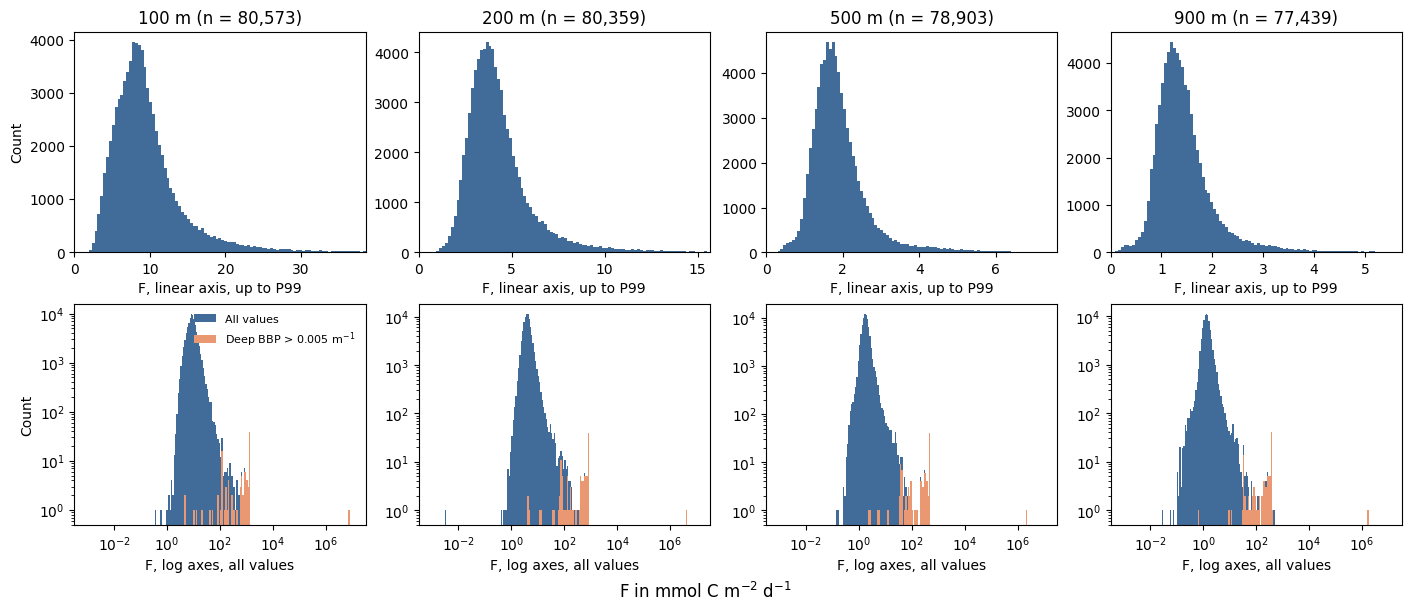

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)
log_bins = np.logspace(-3, 7, 201)

for j, (depth, group) in enumerate(flux.groupby("depth")):
    f = group["F_5_12"]
    p99 = f.quantile(.99)

    axes[0, j].hist(f[f <= p99], bins=100, color="#416c99")
    axes[0, j].set(title=f"{depth} m (n = {len(f):,})", xlim=(0, p99), xlabel="F, linear axis, up to P99")

    axes[1, j].hist(f, bins=log_bins, color="#416c99", label="All values")
    axes[1, j].hist(f[group["high_deep_bbp"]], bins=log_bins, color="#e99871", label="Deep BBP > 0.005 m$^{-1}$")
    axes[1, j].set(xscale="log", yscale="log", ylim=(.5, None), xlabel="F, log axes, all values")

axes[0, 0].set_ylabel("Count")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(frameon=False, fontsize=8)
fig.supxlabel("F in mmol C m$^{-2}$ d$^{-1}$")
fig.savefig(PROJ / "figures/step1_raw_flux_distribution.png", dpi=200)

**Conclusion:**

- Profiles with a positive F: 80,573 at 100 m, 80,359 at 200 m, 78,903 at 500 m and 77,439 at 900 m. No value of F is ≤ 0.
- The median decreases with depth: 8.72, 3.96, 1.78 and 1.35 mmol C m⁻² d⁻¹.
- On a linear axis, all four depths have one peak and a right skew.
- The maximum over all data is 1.7–7.6 × 10⁶, which pulls the means to 106, 59, 28 and 24.
- Leaving out the flagged profiles with high deep BBP (108–111 per depth) gives maxima of 852, 564, 298 and 456 and means of 10.17, 4.57, 2.04 and 1.56. The medians barely change.
- All values above 1000 (47 at 100 m, 1 at each other depth) come from these profiles.

## Step 2: Data cleaning

**Aim:** Apply four rules in order, count what each one removes, and write the rows that pass all of them to `cleaned_data.csv`.

1. F exists. sPOC is the mean over all levels in the window; lPOC is the mean over `zoo_excluded = 0` levels.
2. The profile's median BBP below 500 dbar is not above 0.005 m⁻¹. Profiles with no data below 500 dbar stay in, because the rule cannot judge them.
3. Same-day SST exists.
4. Same-day Chl-a exists.

Low values are not cut, and no percentile or sPOC threshold is applied.

In [9]:
profiles = pd.read_excel(XLSX, sheet_name="profiles", usecols=["cycle_uid", "sst_day", "chl_day"])
table = data.merge(profiles, on="cycle_uid", how="left")

# Each rule is applied after the ones above it
rules = {
    "has F": table["F_5_12"] > 0,
    "deep BBP not high": ~table["high_deep_bbp"],
    "has SST": table["sst_day"] > -2,
    "has Chl-a": table["chl_day"] > 0,
}
keep = pd.Series(True, index=table.index)
steps = {"all rows": table.groupby("depth").size()}
for name, rule in rules.items():
    keep &= rule
    steps[name] = table[keep].groupby("depth").size()
cleaning = pd.DataFrame(steps).T
cleaning

depth,100,200,500,900
all rows,80645,80645,80645,80645
has F,80573,80359,78903,77439
deep BBP not high,80462,80248,78792,77331
has SST,79127,78913,77448,75993
has Chl-a,75276,75062,73614,72170


In [10]:
# Why F is empty, and why Chl-a is missing
no_f = table[table["F_5_12"].isna()]
print(pd.DataFrame({
    "no levels in window": no_f[no_f["n_pts"].fillna(0) == 0].groupby("depth").size(),
    "levels but no sPOC": no_f[(no_f["n_pts"] > 0) & no_f["spoc_mean"].isna()].groupby("depth").size(),
    "sPOC but all lPOC levels zoo": no_f[no_f["spoc_mean"].notna()].groupby("depth").size(),
}).fillna(0).astype(int))
lat = pd.read_excel(XLSX, sheet_name="profiles", usecols=["cycle_uid", "lat", "chl_day"])
print("profiles without same-day Chl-a:", lat["chl_day"].isna().sum(),
      "| without position:", lat["lat"].isna().sum(),
      "| with position, no Chl-a, |lat| > 50:", (lat["chl_day"].isna() & (lat["lat"].abs() > 50)).sum())
print("rows with n_zoo > 0 and a value of F:", ((table["n_zoo"] > 0) & table["F_5_12"].notna()).sum())

       no levels in window  levels but no sPOC  sPOC but all lPOC levels zoo
depth                                                                       
100                     11                  61                             0
200                    255                  31                             0
500                   1708                  32                             2
900                   2531                 674                             1


profiles without same-day Chl-a: 5196 | without position: 1344 | with position, no Chl-a, |lat| > 50: 3850
rows with n_zoo > 0 and a value of F: 1699


In [11]:
cleaned = table.loc[keep, ["cycle_uid", "depth", "F_5_12", "sst_day", "chl_day"]]
cleaned.to_csv(PROJ / "cleaned_data.csv", index=False)
cleaned.groupby("depth").size()

depth
100    75276
200    75062
500    73614
900    72170
dtype: int64

**Conclusion:** `cleaned_data.csv` keeps 75,276 rows at 100 m (93.3%), 75,062 at 200 m (93.1%), 73,614 at 500 m (91.3%) and 72,170 at 900 m (89.5%). The deep BBP rule removes 108–111 rows per depth. The largest loss is missing Chl-a, about 3,850 rows per depth, nearly all at |lat| > 50°, so high latitudes are under-sampled.